# FAO-56 Penman-Monteith ET0 calculator - hourly

Hourly reference evapotranspiration ($ET_0$) for the grass reference crop, following
*FAO Irrigation and Drainage Paper No. 56* (Allen et al., 1998).

**Naming rule:** every variable has the same name as its symbol in FAO-56, in the function
definitions, in `eto_hourly` and in the final equation (`delta`, `gamma`, `Rn`, `G`, `T_hr`, `u2`, `es`, `ea`, ...).

**Inputs per time step:** $T_{hr}$, $T_{dew}$, $u_2$ (wind already at 2 m), $R_s$ (measured).

**Time step $t_1$** (hours): `t1 = 1` for hourly data, `t1 = 0.25` for 15-min data. All energy terms ($R_a$, $R_s$, $R_n$, $G$) are then in MJ m⁻² **per time step**, and $ET_0$ comes out in mm **per time step**.

1. Imports
2. Building-block equations
3. `eto_hourly` + validation against FAO-56 Example 19
4. Your data: the three plots (CF, AG, CA) from the logger CSV
5. Next step: Kc -> actual ET

## 1. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({'font.size': 12})

## 2. Building-block equations

Final equation (FAO-56 Eq. 53, with $C_n = 37$ per hour, so $37\,t_1$ per time step):

$$ET_0 = \dfrac{0.408\,\Delta\,(R_n - G) + \gamma \dfrac{37\,t_1}{T_{hr} + 273}\,u_2\,(e_s - e_a)}{\Delta + \gamma\,(1 + 0.34\,u_2)}$$

| Symbol | Python name | Meaning | Units |
|---|---|---|---|
| $\Delta$ | `delta` | slope of saturation vapour pressure curve | kPa/°C |
| $\gamma$ | `gamma` | psychrometric constant | kPa/°C |
| $R_n$ | `Rn` | net radiation | MJ m⁻² per time step |
| $G$ | `G` | soil heat flux | MJ m⁻² per time step |
| $T_{hr}$ | `T_hr` | air temperature of the time step | °C |
| $t_1$ | `t1` | length of the time step | hour |
| $u_2$ | `u2` | wind speed at 2 m | m/s |
| $e_s$ | `es` | saturation vapour pressure | kPa |
| $e_a$ | `ea` | actual vapour pressure | kPa |

### 2.1 Pressure and psychrometric constant (Eq. 7, 8)
$P = 101.3\left(\dfrac{293 - 0.0065\,z}{293}\right)^{5.26}$, $\quad \gamma = 0.665\times10^{-3}\,P$

In [3]:
def calc_P(z):
    '''Atmospheric pressure P [kPa] from elevation z [m] (Eq. 7).'''
    return 101.3 * ((293 - 0.0065 * z) / 293) ** 5.26


def calc_gamma(P):
    '''Psychrometric constant gamma [kPa/degC] (Eq. 8).'''
    return 0.665e-3 * P

### 2.2 Vapour pressure (Eq. 11, 13, 14)
$e^\circ(T) = 0.6108\exp\left(\dfrac{17.27\,T}{T+237.3}\right)$, $\quad e_s = e^\circ(T_{hr})$, $\quad e_a = e^\circ(T_{dew})$,
$\quad \Delta = \dfrac{4098\,e^\circ(T_{hr})}{(T_{hr}+237.3)^2}$

In [4]:
def calc_e0(T):
    '''Saturation vapour pressure e0(T) [kPa] (Eq. 11).'''
    return 0.6108 * np.exp(17.27 * T / (T + 237.3))


def calc_es(T_hr):
    '''Saturation vapour pressure es [kPa] for the hour (Eq. 11).'''
    return calc_e0(T_hr)


def calc_ea(T_dew):
    '''Actual vapour pressure ea [kPa] from dew point (Eq. 14).'''
    return calc_e0(T_dew)


def calc_delta(T_hr):
    '''Slope of the saturation vapour pressure curve delta [kPa/degC] (Eq. 13).'''
    return 4098 * calc_e0(T_hr) / (T_hr + 237.3) ** 2

### 2.3 Extraterrestrial radiation for the time step (Eq. 23-25, 28-33)
$L_z$, $L_m$ in degrees **west** of Greenwich (UTC+1 → $L_z=-15$). `t` = clock time at the **middle** of the time step (e.g. 14.5 for 14:00-15:00, 14.125 for 14:00-14:15).

Start and end sun angles of the period: $\omega_1 = \omega - \dfrac{\pi\,t_1}{24}$, $\quad \omega_2 = \omega + \dfrac{\pi\,t_1}{24}$ (Eq. 29, 30)

In [5]:
Gsc = 0.0820  # solar constant [MJ m-2 min-1]


def calc_Ra(J, phi, Lz, Lm, t, t1):
    '''Extraterrestrial radiation Ra [MJ m-2 per time step] (Eq. 23-25, 28-33).
    J   : day of year
    phi : latitude [rad]
    Lz, Lm : longitude of time-zone centre / site [deg west of Greenwich]
    t   : clock time at the middle of the time step [h]
    t1  : length of the time step [h] (1 = hourly, 0.25 = 15 min)
    '''
    dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)                    # Eq. 23
    dec = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)                # Eq. 24 (solar declination)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(dec), -1, 1))      # Eq. 25 (sunset hour angle)
    b = 2 * np.pi * (J - 81) / 364                                  # Eq. 33
    Sc = 0.1645 * np.sin(2 * b) - 0.1255 * np.cos(b) - 0.025 * np.sin(b)   # Eq. 32
    w = np.pi / 12 * ((t + 0.06667 * (Lz - Lm) + Sc) - 12)          # Eq. 31
    w1 = np.clip(w - np.pi * t1 / 24, -ws, ws)                           # Eq. 29
    w2 = np.clip(w + np.pi * t1 / 24, -ws, ws)                           # Eq. 30
    w1 = min(w1, w2)
    Ra = 12 * 60 / np.pi * Gsc * dr * ((w2 - w1) * np.sin(phi) * np.sin(dec)
                                       + np.cos(phi) * np.cos(dec) * (np.sin(w2) - np.sin(w1)))  # Eq. 28
    return max(Ra, 0.0)

### 2.4 Radiation balance (Eq. 37-40)
$R_{so} = (0.75 + 2\times10^{-5}z)\,R_a$, $\quad R_{ns} = (1-0.23)\,R_s$

$R_{nl} = \sigma\,t_1\,(T_{hr}+273.16)^4\,(0.34 - 0.14\sqrt{e_a})\,(1.35\,R_s/R_{so} - 0.35)$ — at night $R_s/R_{so}=0.8$ is assumed

$R_n = R_{ns} - R_{nl}$

In [6]:
sigma = 4.903e-9 / 24  # Stefan-Boltzmann constant [MJ K-4 m-2 hour-1] (x t1 -> per time step)


def calc_Rso(Ra, z):
    '''Clear-sky radiation Rso (Eq. 37).'''
    return (0.75 + 2e-5 * z) * Ra


def calc_Rns(Rs):
    '''Net shortwave radiation Rns, albedo 0.23 (Eq. 38).'''
    return (1 - 0.23) * Rs


def calc_Rnl(T_hr, ea, Rs, Rso, t1):
    '''Net longwave radiation Rnl [MJ m-2 per time step] (Eq. 39, sub-daily form).'''
    ratio = np.clip(Rs / Rso, 0.05, 1.0) if Rso > 0 else 0.8
    return sigma * t1 * (T_hr + 273.16) ** 4 * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * ratio - 0.35)


def calc_Rn(Rns, Rnl):
    '''Net radiation Rn (Eq. 40).'''
    return Rns - Rnl

### 2.5 Soil heat flux (Eq. 45, 46)
$G = 0.1\,R_n$ during the day, $G = 0.5\,R_n$ at night ($R_n<0$).

In [7]:
def calc_G(Rn):
    '''Soil heat flux G (Eq. 45 / 46).'''
    return 0.1 * Rn if Rn >= 0 else 0.5 * Rn

### 2.6 Final equation (Eq. 53)

In [8]:
def calc_ET0(delta, gamma, Rn, G, T_hr, u2, es, ea, t1):
    '''Reference evapotranspiration ET0 [mm per time step] (Eq. 53, Cn = 37 * t1).'''
    return (0.408 * delta * (Rn - G) + gamma * 37 * t1 / (T_hr + 273) * u2 * (es - ea)) \
           / (delta + gamma * (1 + 0.34 * u2))

## 3. `eto_hourly`, validated against FAO-56 Example 19

Every intermediate quantity keeps its symbol name, so this reads line by line like the handbook.

In [9]:
def eto_hourly(J, phi_deg, z, Lz, Lm, t, T_hr, ea, u2, Rs, t1=1.0, verbose=False):
    '''FAO-56 sub-daily ET0 [mm per time step].
    t  : clock time at the middle of the time step [h]
    t1 : length of the time step [h] (1 = hourly, 0.25 = 15 min)
    ea : actual vapour pressure [kPa], e.g. calc_ea(T_dew)
    u2 : wind speed at 2 m [m/s]
    Rs : measured solar radiation [MJ m-2 per time step] (0 at night)
    '''
    phi = np.radians(phi_deg)

    P     = calc_P(z)
    gamma = calc_gamma(P)
    es    = calc_es(T_hr)
    delta = calc_delta(T_hr)

    Ra    = calc_Ra(J, phi, Lz, Lm, t, t1)
    Rso   = calc_Rso(Ra, z)
    Rns   = calc_Rns(Rs)
    Rnl   = calc_Rnl(T_hr, ea, Rs, Rso, t1)
    Rn    = calc_Rn(Rns, Rnl)
    G     = calc_G(Rn)

    ET0   = calc_ET0(delta, gamma, Rn, G, T_hr, u2, es, ea, t1)

    if verbose:
        return ET0, dict(gamma=gamma, es=es, ea=ea, delta=delta,
                         Ra=Ra, Rso=Rso, Rnl=Rnl, Rn=Rn, G=G)
    return ET0

**Example 19** (N'Diaye, Senegal: 16°13'N, 16°15'W, z = 8 m, 1 October → J = 274, $L_z$ = 15).
The example gives RH instead of dew point, so here $e_a = e_s \cdot RH/100$ (Eq. 54) — validation only.

In [10]:
J, phi_deg, z, Lz, Lm = 274, 16 + 13/60, 8, 15, 16 + 15/60

ET0_night, s_night = eto_hourly(J, phi_deg, z, Lz, Lm, t=2.5,
                                T_hr=28, ea=calc_es(28) * 0.90, u2=1.9, Rs=0.0, t1=1, verbose=True)
ET0_day, s_day = eto_hourly(J, phi_deg, z, Lz, Lm, t=14.5,
                            T_hr=38, ea=calc_es(38) * 0.52, u2=3.3, Rs=2.450, t1=1, verbose=True)

fao = {
    'night (02:00-03:00)':     dict(gamma=0.0673, es=3.780, ea=3.402, delta=0.220, Ra=0.0,   Rso=0.0,
                                    Rnl=0.100, Rn=-0.100, G=-0.050, ET0=0.00),
    'afternoon (14:00-15:00)': dict(gamma=0.0673, es=6.625, ea=3.445, delta=0.358, Ra=3.543, Rso=2.658,
                                    Rnl=0.137, Rn=1.749,  G=0.175,  ET0=0.63),
}

for (label, ref), ET0, s in zip(fao.items(), [ET0_night, ET0_day], [s_night, s_day]):
    print(f"--- {label} ---\n{'':<8}{'notebook':>10}{'FAO-56':>10}")
    for k in ['gamma', 'es', 'ea', 'delta', 'Ra', 'Rso', 'Rnl', 'Rn', 'G']:
        print(f"{k:<8}{s[k]:>10.3f}{ref[k]:>10.3f}")
    print(f"{'ET0':<8}{ET0:>10.3f}{ref['ET0']:>10.3f}\n")

--- night (02:00-03:00) ---
          notebook    FAO-56
gamma        0.067     0.067
es           3.780     3.780
ea           3.402     3.402
delta        0.220     0.220
Ra           0.000     0.000
Rso          0.000     0.000
Rnl          0.100     0.100
Rn          -0.100    -0.100
G           -0.050    -0.050
ET0          0.004     0.000

--- afternoon (14:00-15:00) ---
          notebook    FAO-56
gamma        0.067     0.067
es           6.625     6.625
ea           3.445     3.445
delta        0.358     0.358
Ra           3.543     3.543
Rso          2.658     2.658
Rnl          0.137     0.137
Rn           1.749     1.749
G            0.175     0.175
ET0          0.627     0.630



Both hours match the handbook (FAO-56 prints ET0 rounded to 2 decimals).

**Check for 15-min steps:** with the same conditions held constant over the hour, four 15-min steps
($t_1 = 0.25$, Rs split in four) should add up to about the hourly value.

In [11]:
ET0_15 = sum(eto_hourly(J, phi_deg, z, Lz, Lm, t=14 + 0.125 + 0.25 * i,
                        T_hr=38, ea=calc_es(38) * 0.52, u2=3.3, Rs=2.450 / 4, t1=0.25)
             for i in range(4))
print(f"1 x 60 min : {ET0_day:.3f} mm")
print(f"4 x 15 min : {ET0_15:.3f} mm")

1 x 60 min : 0.627 mm
4 x 15 min : 0.627 mm


## 4. Your data: the three plots from the logger CSV

All three plots come from **one CSV** with one `Timestamp` column. For each plot you list which columns to use:

| Plot | Temperature / humidity | Solar radiation | Wind | Rain (kept for later) |
|---|---|---|---|---|
| **CF** | HOBO: $T$ + dew point → $e_a$ (Eq. 14) | HOBO | HOBO | HOBO open sky |
| **AG** | TEMPEST: $T$ + RH → $e_a$ (Eq. 54) | TEMPEST | TEMPEST | TEMPEST |
| **CA** | TEMPEST: $T$ + RH → $e_a$ (Eq. 54) | TEMPEST | TEMPEST | Tipping bucket 5 |

- **Duplicate sensors:** when you give several columns for one variable, they are **averaged** for every time step.
  If one sensor has a gap (NaN), the others are still used. To add a new logger, add its column name to the list.
- **15-min data:** the FAO-56 equations stay the same. Only the time step changes, through `t1 = 0.25`
  (sun angles in $R_a$, longwave $R_{nl}$, and $37\,t_1$ in Eq. 53). $R_s$ is converted from W m⁻² to MJ m⁻² per 15 min.
- AG and CA use the same TEMPEST weather, so their **ET0 is identical**. They only differ once Kc is applied (section 5).

### 4.1 Settings - the only cell you need to edit

In [12]:
DATA_FILE = 'loggers_20261001-20261017_1h.csv'

# --- site (TODO: check these) --------------------------------------------------------
phi_deg = 15.37    # latitude [deg N]                                   
Lm      = 90.35    # longitude of the site [deg WEST of Greenwich]      
Lz      = 90.0     # centre of the time zone, UTC-6 -> 90 deg W

# --- time step ------------------------------------------------------------------------
t1    = 1       # length of one time step [h]: 0.25 = 15 min, 1 = hourly
STAMP = 'start'    # does Timestamp mark the 'start' or the 'end' of the interval?  

# --- analysis period (local time) -----------------------------------------------------
START = '2026-10-01 23:00'
END   = '2026-10-18 00:00'

# --- which columns belong to which plot (several columns -> averaged) ------------------
PLOTS = {
    'CF': dict(z=1650,
               T     = ['HOBO_CF_Temp_13.5m_C_21981341'],
               T_dew = ['HOBO_DewPoint_21981341_C',], #at 13.5 m 
               Rs    = ['HOBO_Solar_22278678_Wm2'], #at 13.5 m 
               u2    = ['OPENMETEO_u2_CF_ms']),
    'AF': dict(z=1420,
               T     = ['TEMPEST_Temp_C'],
               RH    = ['TEMPEST_RH_Pct'],
               Rs    = ['TEMPEST_Solar_Wm2'],
               u2    = ['TEMPEST_WindSpeed_ms']),
    'CA': dict(z=1690,
               T     = ['LOGTAG-CA1_Temp_C',     'LOGTAG-CA2_Temp_C'], 
               RH    = ['LOGTAG-CA1_RH_Pct',     'LOGTAG-CA2_RH_Pct'], 
               Rs    = ['TEMPEST_Solar_Wm2'], 
               u2    = ['OPENMETEO_u2_CA_ms']),
}

### 4.2 Read the CSV and build the inputs of each plot

`J` and `t` come from the timestamp, taken at the **middle** of each time step
(`+ t1/2` if the timestamp marks the start of the interval, `- t1/2` if it marks the end).

In [13]:
raw = pd.read_csv(DATA_FILE, parse_dates=['Timestamp']).set_index('Timestamp').sort_index()

# keep only the analysis period (exactly 16 x 24 h, whatever the timestamp convention)
if STAMP == 'start':
    raw = raw[(raw.index >= START) & (raw.index < END)]
else:
    raw = raw[(raw.index > START) & (raw.index <= END)]
print('raw:', raw.index.min(), '->', raw.index.max(), f'({len(raw)} rows)')

# Vent AMBIENT : seulement s'il n'est pas déjà dans DATA_FILE
if 'AMBIENT_WindSpeed_ms' not in raw.columns:
    amb = pd.read_csv(AMBIENT_FILE, parse_dates=['Timestamp']).set_index('Timestamp').sort_index()
    raw['AMBIENT_WindSpeed_ms'] = amb['<nom colonne vent>'].resample('h').mean().reindex(raw.index)

print(raw['AMBIENT_WindSpeed_ms'].describe())   # contrôle rapide : m/s, valeurs plausibles

raw: 2026-10-01 23:00:00 -> 2026-10-17 23:00:00 (385 rows)
count    385.000000
mean       0.040601
std        0.101709
min        0.000000
25%        0.000000
50%        0.000000
75%        0.033155
max        0.758478
Name: AMBIENT_WindSpeed_ms, dtype: float64


In [14]:
import requests

def openmeteo_wind(lat, lon):
    '''Hourly 10 m and 100 m model wind [m/s] from Open-Meteo, local time.'''
    r = requests.get('https://archive-api.open-meteo.com/v1/archive', params=dict(
        latitude=lat, longitude=lon,
        start_date=raw.index.min().strftime('%Y-%m-%d'),
        end_date=raw.index.max().strftime('%Y-%m-%d'),
        hourly='wind_speed_10m,wind_speed_100m', wind_speed_unit='ms',
        timezone='America/Guatemala'), timeout=30)
    r.raise_for_status()
    om  = r.json()['hourly']
    idx = pd.to_datetime(om['time'])
    return (pd.Series(om['wind_speed_10m'],  index=idx, dtype=float),
            pd.Series(om['wind_speed_100m'], index=idx, dtype=float))

def to_raw_index(s):
    '''Put a series on the logger timestamps (interpolated if 15-min).'''
    return s.reindex(s.index.union(raw.index)).interpolate('time').reindex(raw.index)

# CF: 100 m model wind used directly as u2
u10, u100 = openmeteo_wind(15.364401682593286, -90.34411492229958)
raw['OPENMETEO_u2_CF_ms'] = to_raw_index(u100)

# CA: 100 m model wind used directly as u2
u10, u100 = openmeteo_wind(15.366104, -90.354231)     # west -> negative longitude
raw['OPENMETEO_u2_CA_ms'] = to_raw_index(u100)

print(raw[['OPENMETEO_u2_CF_ms', 'OPENMETEO_u2_CA_ms']].isna().sum())


OPENMETEO_u2_CF_ms    0
OPENMETEO_u2_CA_ms    0
dtype: int64


In [15]:
def fill_lin(df, target, predictor, clip=None, min_r=0.8, window=None):
    '''Remplit les NaN de `target` par une régression linéaire sur `predictor` (heures communes).'''
    ok = df[[target, predictor]].dropna()
    r = ok.corr().iloc[0, 1]
    a, b = np.polyfit(ok[predictor], ok[target], 1)
    mask = df[target].isna() & df[predictor].notna()
    if window:
        mask &= (df.index >= window[0]) & (df.index <= window[1])
    print(f"{target:24s} ← {predictor:26s} r={r:.2f}  y={a:.2f}x{b:+.2f}  {mask.sum()} h")
    if r < min_r:
        print("   r trop faible → pas rempli"); return mask & False
    vals = a * df.loc[mask, predictor] + b
    df.loc[mask, target] = vals.clip(*clip) if clip else vals
    return mask

filled = {}   # masques des valeurs remplies (hors de raw)

# AF : trous TEMPEST (8 et 12 oct.) ← AMBIENT, même parcelle
filled['TEMPEST_Temp_C']    = fill_lin(raw, 'TEMPEST_Temp_C',    'AMBIENT_Temp_C')
filled['TEMPEST_RH_Pct']    = fill_lin(raw, 'TEMPEST_RH_Pct',    'AMBIENT_RH_Pct',    clip=(0, 100))
filled['TEMPEST_Solar_Wm2'] = fill_lin(raw, 'TEMPEST_Solar_Wm2', 'AMBIENT_Solar_Wm2', clip=(0, None))

# vent TEMPEST : AMBIENT d'abord, Open-Meteo en secours
filled['TEMPEST_WindSpeed_ms']  = fill_lin(raw, 'TEMPEST_WindSpeed_ms', 'AMBIENT_WindSpeed_ms',
                                           clip=(0, None), min_r=0.5)
filled['TEMPEST_WindSpeed_ms'] |= fill_lin(raw, 'TEMPEST_WindSpeed_ms', 'OPENMETEO_u2_CA_ms',
                                           clip=(0, None), min_r=0)

# AMBIENT : trous du 13 oct. ← TEMPEST
filled['AMBIENT_Temp_C']    = fill_lin(raw, 'AMBIENT_Temp_C',    'TEMPEST_Temp_C')
filled['AMBIENT_RH_Pct']    = fill_lin(raw, 'AMBIENT_RH_Pct',    'TEMPEST_RH_Pct',    clip=(0, 100))
filled['AMBIENT_Solar_Wm2'] = fill_lin(raw, 'AMBIENT_Solar_Wm2', 'TEMPEST_Solar_Wm2', clip=(0, None))

# CA : les LOGTAG s'arrêtent le 12 oct. ← TEMPEST (hypothèse plus forte : station de vallée)
FILL_CA_FROM_TEMPEST = True
CA_WINDOW = ('2026-10-12 00:00', '2026-10-13 23:00')
if FILL_CA_FROM_TEMPEST:
    for lg in ['LOGTAG-CA1', 'LOGTAG-CA2']:
        filled[f'{lg}_Temp_C'] = fill_lin(raw, f'{lg}_Temp_C', 'TEMPEST_Temp_C', window=CA_WINDOW)
        filled[f'{lg}_RH_Pct'] = fill_lin(raw, f'{lg}_RH_Pct', 'TEMPEST_RH_Pct', clip=(0, 100), window=CA_WINDOW)

# heures remplies par jour
fill_summary = pd.DataFrame(filled).resample('D').sum()
print(fill_summary.loc[:, fill_summary.sum() > 0])

TEMPEST_Temp_C           ← AMBIENT_Temp_C             r=1.00  y=0.92x+1.34  20 h
TEMPEST_RH_Pct           ← AMBIENT_RH_Pct             r=1.00  y=0.74x+24.62  20 h
TEMPEST_Solar_Wm2        ← AMBIENT_Solar_Wm2          r=0.99  y=1.32x+4.86  20 h
TEMPEST_WindSpeed_ms     ← AMBIENT_WindSpeed_ms       r=0.53  y=1.40x+0.30  20 h
TEMPEST_WindSpeed_ms     ← OPENMETEO_u2_CA_ms         r=0.08  y=0.01x+0.32  0 h
AMBIENT_Temp_C           ← TEMPEST_Temp_C             r=1.00  y=1.08x-1.35  0 h
AMBIENT_RH_Pct           ← TEMPEST_RH_Pct             r=1.00  y=1.34x-32.09  0 h
AMBIENT_Solar_Wm2        ← TEMPEST_Solar_Wm2          r=0.99  y=0.75x-2.29  0 h
LOGTAG-CA1_Temp_C        ← TEMPEST_Temp_C             r=0.92  y=1.08x-2.19  0 h
LOGTAG-CA1_RH_Pct        ← TEMPEST_RH_Pct             r=0.93  y=1.25x-22.15  0 h
LOGTAG-CA2_Temp_C        ← TEMPEST_Temp_C             r=0.86  y=1.10x-2.19  0 h
LOGTAG-CA2_RH_Pct        ← TEMPEST_RH_Pct             r=0.86  y=1.26x-24.06  0 h
            TEMPEST_Temp_C  TEMP

In [16]:
half = pd.Timedelta(hours=t1 / 2)
mid  = raw.index + half if STAMP == 'start' else raw.index - half   # middle of each time step
J    = mid.dayofyear
t    = mid.hour + mid.minute / 60 + mid.second / 3600


def plot_inputs(cols):
    '''ET0 inputs for one plot. Several sensors for one variable -> mean (NaN ignored).'''
    d = pd.DataFrame(index=raw.index)
    d['J'] = J
    d['t'] = t
    d['T_hr'] = raw[cols['T']].mean(axis=1)
    if 'T_dew' in cols:
        d['ea'] = calc_ea(raw[cols['T_dew']].mean(axis=1))                       # Eq. 14
    else:
        d['ea'] = calc_e0(d['T_hr']) * raw[cols['RH']].mean(axis=1) / 100        # Eq. 54
    d['ea'] = np.minimum(d['ea'], calc_es(d['T_hr']))   # ea cannot exceed es
    d['u2'] = raw[cols['u2']].mean(axis=1)
    d['Rs'] = raw[cols['Rs']].mean(axis=1).clip(lower=0) * t1 * 3600 / 1e6   # W m-2 -> MJ m-2 per step
    return d


inputs = {plot: plot_inputs(cols) for plot, cols in PLOTS.items()}
pd.concat(inputs, axis=1).swaplevel(axis=1).sort_index(axis=1).head(10)

inputs = {plot: plot_inputs(cols) for plot, cols in PLOTS.items()}

# contrôle : heures encore manquantes par jour et par parcelle (24 = jour complet)
for p, d in inputs.items():
    n = d[['T_hr', 'ea', 'u2', 'Rs']].notna().all(axis=1).resample('D').sum()
    print(p, n[n < 24].to_dict())

CF {Timestamp('2026-10-01 00:00:00'): 1}
AF {Timestamp('2026-10-01 00:00:00'): 1}
CA {Timestamp('2026-10-01 00:00:00'): 1}


### 4.3 ET0 for every time step and every plot

In [17]:
results = {}
for plot, d in inputs.items():
    z = PLOTS[plot]['z']
    d['ET0'] = [eto_hourly(r.J, phi_deg, z, Lz, Lm, r.t, r.T_hr, r.ea, r.u2, r.Rs, t1)
                for r in d.itertuples()]
    d['ET0'] = d['ET0'].clip(lower=0) 
    d['Rso'] = [calc_Rso(z, calc_Ra(r.J, phi_deg, Lz, Lm, r.t, t1))      # <- same as inside eto_hourly
                for r in d.itertuples()]
    results[plot] = d

# one long table: plot | Timestamp | inputs | ET0 [mm per time step]
out = pd.concat(results, names=['plot', 'Timestamp']).reset_index()

# ET0 per time step: one row per timestamp, one column per plot
unit = 'mm/h' if t1 == 1 else f'mm/{int(round(t1 * 60))}min'
hourly = out.pivot(index='Timestamp', columns='plot', values='ET0')
hourly.columns = [f'{p} ET0 [{unit}]' for p in hourly.columns]

# daily totals [mm/day], only for complete days (all time steps present)
steps_per_day = int(round(24 / t1))
daily = (out.set_index('Timestamp').groupby('plot')['ET0']
            .resample('D').agg(['sum', 'count']))
daily = daily[daily['count'] == steps_per_day]['sum'].unstack('plot')
daily.columns = [f'{p} ET0 [mm/day]' for p in daily.columns]

display(hourly.round(3))
display(daily.round(2))

,AF ET0 [mm/h],CA ET0 [mm/h],CF ET0 [mm/h]
Timestamp,,,
2026-10-01 23:00:00,0.0,0.0,0.0
2026-10-02 00:00:00,0.0,0.0,0.0
2026-10-02 01:00:00,0.0,0.0,0.0
2026-10-02 02:00:00,0.0,0.0,0.0
2026-10-02 03:00:00,0.0,0.0,0.0
...,...,...,...
2026-10-17 19:00:00,0.0,0.0,0.0
2026-10-17 20:00:00,0.0,0.0,0.0
2026-10-17 21:00:00,0.0,0.0,0.0


,AF ET0 [mm/day],CA ET0 [mm/day],CF ET0 [mm/day]
Timestamp,,,
2026-10-02,3.62,3.68,1.79
2026-10-03,2.17,2.14,1.00
2026-10-04,1.69,1.69,0.86
2026-10-05,3.37,3.55,2.06
2026-10-06,2.69,2.73,1.27
2026-10-07,2.84,2.90,1.42
2026-10-08,2.35,2.32,1.04
2026-10-09,2.65,2.68,1.30
2026-10-10,1.28,1.21,0.63


### 4.4 ET0 in function of time, per plot

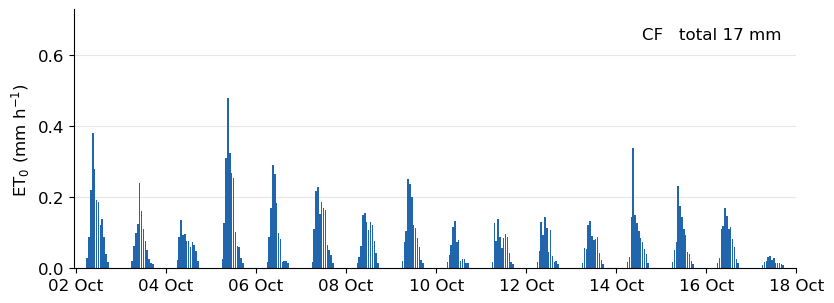

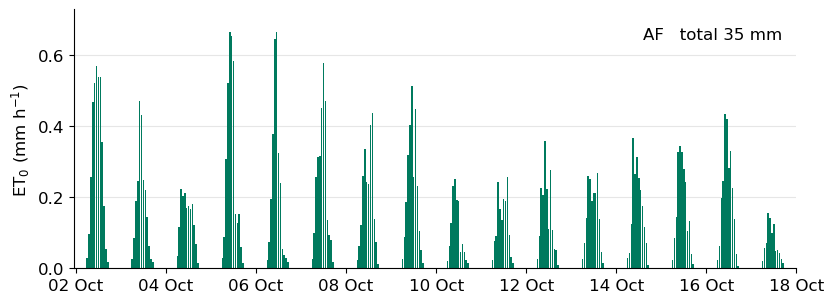

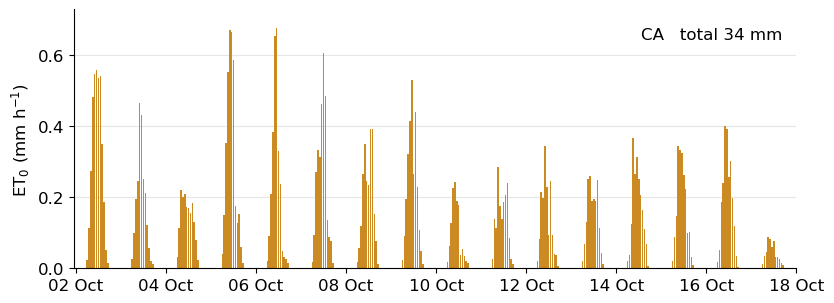

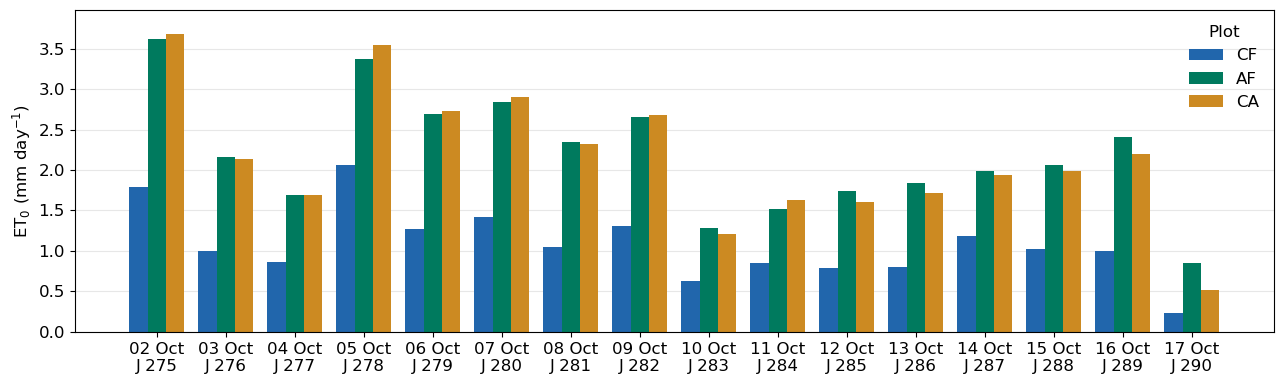

In [18]:
COLORS = {'CF': "#2166AC", 'AF': "#007A5E", 'CA': "#CC8A22"}

import matplotlib.dates as mdates

unit = r'mm h$^{-1}$' if t1 == 1 else f'mm / {int(t1 * 60)} min'
YMAX_H = max(results[p]['ET0'].max() for p in PLOTS) * 1.08     # same y-axis for all plots
YMAX_DAY = daily.max().max() * 1.08                         # same y-axis for daily ET0 and daily potential ETc
XLIM = (pd.Timestamp(START), pd.Timestamp(END))   # same x-axis for all plots

for plot in PLOTS:
    d = results[plot]
    fig, ax = plt.subplots(figsize=(8.5, 3.2))

    ax.bar(d.index, d['ET0'], width=0.8 * t1 / 24, color=COLORS[plot])   # one bar per time step

    # style as in the precipitation figure
    ax.set_ylim(0, YMAX_H)
    ax.set_xlim(*XLIM)                                                          # ← nouveau
    ax.set_ylabel(f'ET$_0$ ({unit})')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='0.9')
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(2, 32, 2)))   # ← remplace interval=2
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.text(0.98, 0.93, f'{plot}   total {d["ET0"].sum():.0f} mm', transform=ax.transAxes,
            ha='right', va='top')

    plt.tight_layout()
    fig.savefig(f'ET0_hourly_{plot}.png', dpi=300, bbox_inches='tight')
    plt.show()

# daily totals: the three plots together (bars)
n     = len(PLOTS)
width = 0.8 / n
x     = np.arange(len(daily))

fig, ax = plt.subplots(figsize=(13, 4))
for k, plot in enumerate(PLOTS):
    ax.bar(x + (k - (n - 1) / 2) * width, daily[f'{plot} ET0 [mm/day]'], width=width,
           color=COLORS[plot], label=plot)
ax.set_xticks(x, labels=[f"{d:%d %b}\nJ {d.dayofyear}" for d in daily.index])
ax.set_ylabel('ET$_0$ (mm day$^{-1}$)')
ax.set_ylim(0, YMAX_DAY)
ax.legend(title='Plot', frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('ET0_daily_per_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [19]:
rh = raw[['HOBO_CF_RH_13.5m_Pct_21981341', 'LOGTAG-CA1_RH_Pct', 'LOGTAG-CA2_RH_Pct', 'TEMPEST_RH_Pct']]
rh.groupby(rh.index.hour).median().round(1)

,HOBO_CF_RH_13.5m_Pct_21981341,LOGTAG-CA1_RH_Pct,LOGTAG-CA2_RH_Pct,TEMPEST_RH_Pct
Timestamp,,,,
0,100.0,100.0,100.0,98.0
1,100.0,100.0,100.0,98.0
2,100.0,100.0,100.0,98.0
3,100.0,100.0,100.0,98.0
4,100.0,100.0,100.0,98.0
5,100.0,100.0,100.0,98.0
6,100.0,100.0,100.0,98.0
7,99.5,97.5,94.7,98.0
8,97.5,90.8,85.2,94.1


### 4.5 Save the results

In [20]:
out.to_csv('ET0_results_hourly.csv', index=False)


## 5. Next step: Kc → actual evapotranspiration

FAO-56 Eq. 56: $ET_c = K_c \cdot ET_0$ (and $ET_{c,adj} = K_s\,K_c\,ET_0$ with water stress, Eq. 80).
Once the Kc values are known, they plug into the same `out` table:

```python
out['Kc']  = out['plot'].map(KC)
out['ETc'] = out['Kc'] * out['ET0']
```

In [21]:
# --- Kc per plot ---------------------------------------------------------------
KC_CF = pd.read_csv('Kc_CF.csv', index_col=0).loc['Kc_now', 'CF']      # from the Kc notebook (section 7)
Kc_AF = pd.read_csv('Kc_AF.csv', index_col=0).loc['Kc_now', 'AF']      # constant, current stage of each species
kc_CA = pd.read_csv('Kc_daily_maize_CCFC.csv', index_col='J')['Kc']    # daily maize curve (FAO-56 Eq. 66)
KC_CA_AFTER_CUT = 0.90    # bare soil after cut-down (13 Oct): FAO-56 Fig. 29, wetting every 1-2 days, ET0 of the period

# day of year of each hourly value (the J column of the ET0 calculation, otherwise from the timestamp)
J_hr = out['J'] if 'J' in out else pd.to_datetime(out['Timestamp']).dt.dayofyear

out['Kc'] = np.nan
out.loc[out['plot'] == 'CF', 'Kc'] = KC_CF
out.loc[out['plot'] == 'AF', 'Kc'] = Kc_AF
is_CA = out['plot'] == 'CA'
out.loc[is_CA, 'Kc'] = J_hr[is_CA].map(kc_CA).fillna(KC_CA_AFTER_CUT)

out['ETc_pot'] = out['Kc'] * out['ET0']      # potential ETc, FAO-56 Eq. 56 [mm/h] (before interception)

print(f'Kc used: CF = {KC_CF}, AF = {Kc_AF:.3f}, '
      f'CA = {kc_CA.loc[J_hr[is_CA].min():J_hr[is_CA].max()].min():.2f}-'
      f'{kc_CA.loc[J_hr[is_CA].min():J_hr[is_CA].max()].max():.2f} (daily curve)')
missing = out.loc[out['Kc'].isna(), 'plot'].value_counts()
if len(missing):
    print('No Kc (ETc_pot = NaN) for:', missing.to_dict(), '<- other plot names, or CA after the cut-down')

Kc used: CF = 0.8398688351476808, AF = 0.862, CA = 0.35-0.47 (daily curve)


ET0  ETc_pot  Kc_mean
plot J_day                        
AF   274    0.00     0.00     0.86
     275    3.62     3.12     0.86
     276    2.17     1.87     0.86
     277    1.69     1.45     0.86
     278    3.37     2.90     0.86
     279    2.69     2.32     0.86
     280    2.84     2.45     0.86
     281    2.35     2.02     0.86
     282    2.65     2.28     0.86
     283    1.28     1.10     0.86
     284    1.52     1.31     0.86
     285    1.74     1.50     0.86
     286    1.83     1.58     0.86
     287    1.99     1.72     0.86
     288    2.07     1.78     0.86
     289    2.41     2.08     0.86
     290    0.85     0.74     0.86
CA   274    0.00     0.00     0.47
     275    3.68     1.65     0.45
     276    2.14     0.92     0.43
     277    1.69     0.69     0.41
     278    3.55     1.38     0.39
     279    2.73     1.01     0.37
     280    2.90     1.01     0.35
     281    2.32     0.81     0.35
     282    2.68     0.94     0.35
     283    1.21     0.42     0.35
     284    1.63     0.57     0.35
     285    1.61     0.56     0.35
     286    1.72     1.55     0.90
     287    1.94     1.74     0.90
     288    1.99     1.79     0.90
     289    2.20     1.98     0.90
     290    0.51     0.46     0.90
CF   274    0.00     0.00     0.84
     275    1.79     1.50     0.84
     276    1.00     0.84     0.84
     277    0.86     0.72     0.84
     278    2.06     1.73     0.84
     279    1.27     1.07     0.84
     280    1.42     1.19     0.84
     281    1.04     0.88     0.84
     282    1.30     1.10     0.84
     283    0.63     0.53     0.84
     284    0.85     0.71     0.84
     285    0.79     0.66     0.84
     286    0.80     0.67     0.84
     287    1.18     0.99     0.84
     288    1.02     0.86     0.84
     289    1.00     0.84     0.84
     290    0.24     0.20     0.84

Total over the period [mm]:


,ET0,ETc_pot
plot,,
AF,35.1,30.2
CA,34.5,17.5
CF,17.2,14.5


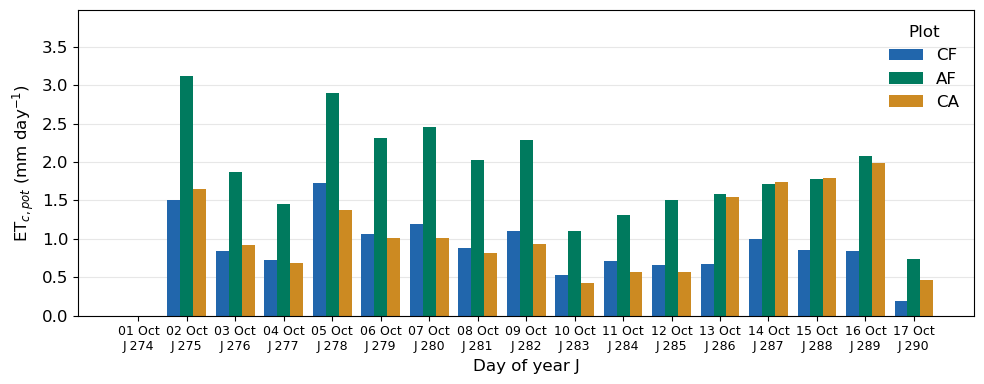

In [22]:
out['J_day'] = J_hr
daily_etc = out.groupby(['plot', 'J_day'])[['ET0', 'ETc_pot']].sum(min_count=1)   # [mm/day]
daily_etc['Kc_mean'] = out.groupby(['plot', 'J_day'])['Kc'].mean()

display(daily_etc.round(2))
print('Total over the period [mm]:')
display(daily_etc.groupby('plot')[['ET0', 'ETc_pot']].sum(min_count=1).round(1))

# daily potential ETc per plot (bars)
dETc  = daily_etc['ETc_pot'].unstack('plot').reindex(columns=PLOTS)   # rows = J, columns = plots in your order
n     = len(PLOTS)
width = 0.8 / n
x     = np.arange(len(dETc))

fig, ax = plt.subplots(figsize=(10, 4))
for k, plot in enumerate(PLOTS):
    ax.bar(x + (k - (n - 1) / 2) * width, dETc[plot], width=width, color=COLORS[plot], label=plot)
YEAR = 2026
ax.set_xticks(x, labels=[f"{pd.Timestamp(YEAR, 1, 1) + pd.Timedelta(days=int(j) - 1):%d %b}\nJ {int(j)}"
                         for j in dETc.index], fontsize=9)
ax.set_xlabel('Day of year J')
ax.set_ylabel(r'ET$_{c,pot}$ (mm day$^{-1}$)')
ax.set_ylim(0, YMAX_DAY)
ax.legend(title='Plot', frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('ETc_pot_daily_per_plot.png', dpi=300, bbox_inches='tight')
plt.show()

out.to_csv('ETc_pot_results_hourly.csv', index=False)   # hourly ET0, Kc and potential ETc per plot

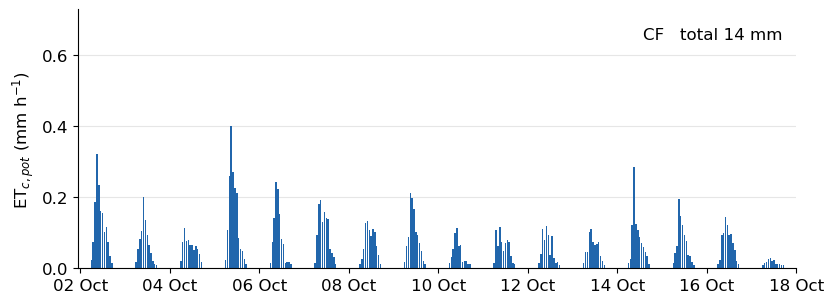

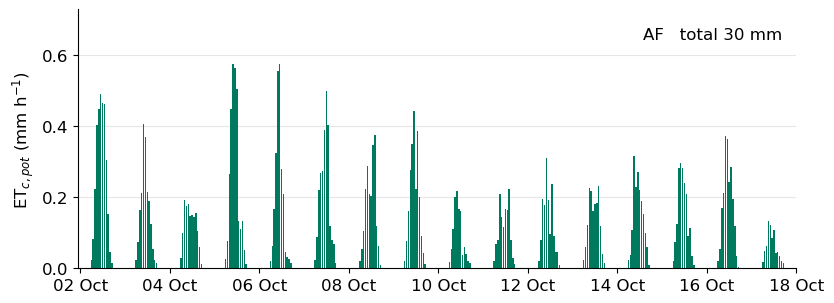

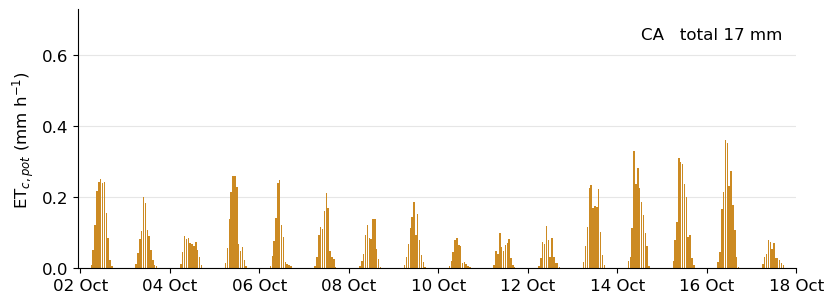

In [23]:
import matplotlib.dates as mdates

unit = r'mm h$^{-1}$' if t1 == 1 else f'mm / {int(t1 * 60)} min'
ts   = pd.to_datetime(out['Timestamp']) if 'Timestamp' in out else out.index.to_series()
ymax = YMAX_H                                   # same y-axis for all plots

for plot in PLOTS:
    m = out['plot'] == plot
    d = pd.Series(out.loc[m, 'ETc_pot'].values, index=ts[m].values).sort_index()

    fig, ax = plt.subplots(figsize=(8.5, 3.2))
    ax.bar(d.index, d.values, width=0.8 * t1 / 24, color=COLORS[plot])   # one bar per time step

    # same style as the ET0 and precipitation figures
    ax.set_ylim(0, ymax)
    ax.set_xlim(*XLIM)                          # same x-axis as the ET0 figures
    ax.set_ylabel(f'ET$_{{c,pot}}$ ({unit})')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='0.9')
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(2, 32, 2)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.text(0.98, 0.93, f'{plot}   total {d.sum():.0f} mm', transform=ax.transAxes,
            ha='right', va='top')

    plt.tight_layout()
    fig.savefig(f'ETc_pot_hourly_{plot}.png', dpi=300, bbox_inches='tight')
    plt.show()

In [24]:
ts = pd.to_datetime(out['Timestamp']) if 'Timestamp' in out else out.index.to_series()
check = out.assign(ts=ts).groupby('plot').agg(first=('ts', 'min'), last=('ts', 'max'), n_hours=('ET0', 'count'),
                                              ET0_max=('ET0', 'max'), ETc_pot_max=('ETc_pot', 'max'),
                                              Kc_min=('Kc', 'min'), Kc_max=('Kc', 'max'))
check['ETc_pot/ET0 at max'] = check['ETc_pot_max'] / check['ET0_max']
display(check)

,first,last,n_hours,ET0_max,ETc_pot_max,Kc_min,Kc_max,ETc_pot/ET0 at max
plot,,,,,,,,
AF,2026-10-01 23:00:00,2026-10-17 23:00:00,385,0.666692,0.574511,0.861733,0.861733,0.861733
CA,2026-10-01 23:00:00,2026-10-17 23:00:00,385,0.676494,0.360872,0.350000,0.900000,0.533444
CF,2026-10-01 23:00:00,2026-10-17 23:00:00,385,0.478899,0.402212,0.839869,0.839869,0.839869


Days used per plot: {'AF': 16, 'CA': 16, 'CF': 16}


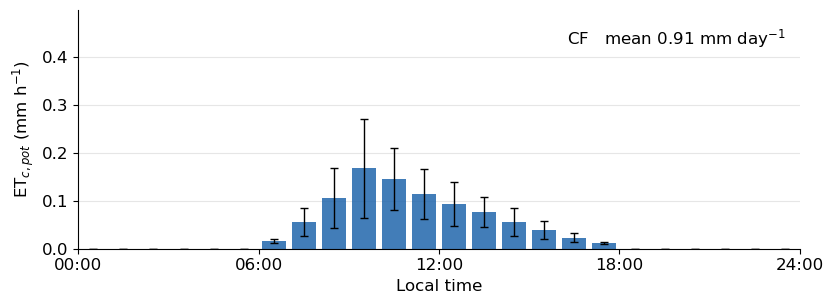

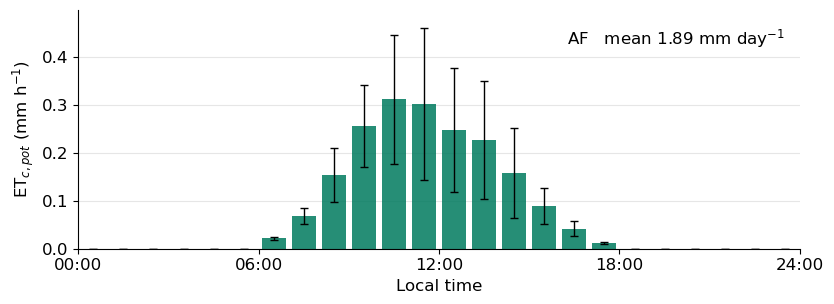

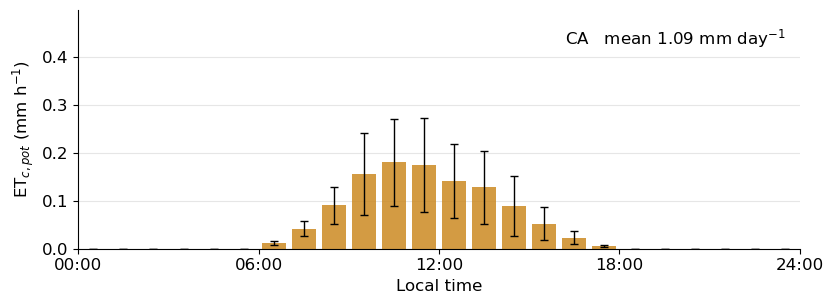

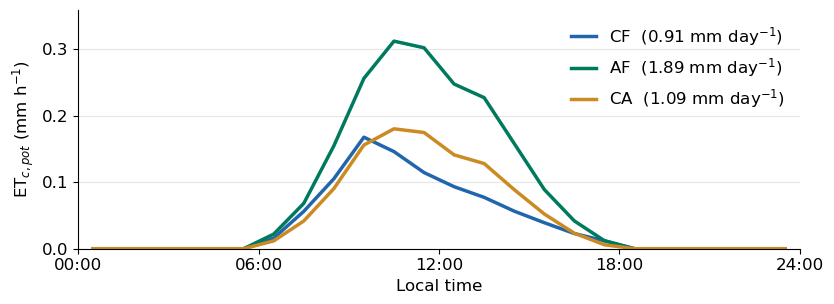

In [25]:
# Mean diurnal cycle of the POTENTIAL ETc per plot (mean ± 1 SD between days)
COMPLETE_DAYS_ONLY = True        # only days with 24 hourly ETc values

ts  = pd.to_datetime(out['Timestamp'])
mid = ts - pd.Timedelta(hours=t1 / 2) if STAMP == 'end' else ts + pd.Timedelta(hours=t1 / 2)
dc  = out.assign(hour=np.floor(out['t']).astype(int), date=mid.dt.date)   # hour = start of the interval

if COMPLETE_DAYS_ONLY:
    dc = dc[dc.groupby(['plot', 'date'])['ETc_pot'].transform('count') == int(round(24 / t1))]
print('Days used per plot:', dc.groupby('plot')['date'].nunique().to_dict())

diurnal   = dc.groupby(['plot', 'hour'])['ETc_pot'].agg(['mean', 'std'])
daily_mean = dc.groupby(['plot', 'date'])['ETc_pot'].sum().groupby('plot').mean()  # [mm/day]
YMAX_D    = (diurnal['mean'] + diurnal['std'].fillna(0)).max() * 1.08            # common y-axis for ALL diurnal bar figures
ymax = (diurnal['mean'] + diurnal['std']).max() * 1.05                             # same y-axis everywhere


def draw(ax, plot):
    '''Mean diurnal ETc of one plot (line) with ±1 SD band; plotted at the middle of each hour.'''
    m, s = diurnal.loc[plot, 'mean'], diurnal.loc[plot, 'std']
    x = m.index + t1 / 2
    ax.plot(x, m, color=COLORS[plot], lw=1.8, label=f'{plot} ({daily_mean[plot]:.2f} mm day$^{{-1}}$)')
    ax.fill_between(x, (m - s).clip(lower=0), m + s, color=COLORS[plot], alpha=0.15, lw=0)


def style(ax):
    ax.set_xlabel('Hour of day (local time)')
    ax.set_ylabel(r'ET$_{c,pot}$ (mm h$^{-1}$)')
    ax.set_xticks(range(0, 25, 3))
    ax.set_xlim(0, 24)
    ax.set_ylim(0, ymax)
    ax.grid(color='0.9')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, loc='upper left')


# ---- plotting ------------------------------------------------------------------------------
per_day = dc.pivot_table(index='hour', columns=['plot', 'date'], values='ETc_pot')   # one column per day
x = per_day.index + t1 / 2                                                        # middle of each hour

TICKS = range(0, 25, 6)


def style(ax, ymax):
    ax.set_xlim(0, 24)
    ax.set_ylim(0, ymax)
    ax.set_xticks(TICKS, labels=[f'{h:02d}:00' for h in TICKS])
    ax.set_xlabel('Local time')
    ax.set_ylabel(r'ET$_{c,pot}$ (mm h$^{-1}$)')
    ax.grid(axis='y', color='0.9')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


# one figure per plot: mean hourly ETc (bars) with ±1 SD between days
ymax_bars = YMAX_D
for plot in PLOTS:
    m, s = diurnal.loc[plot, 'mean'], diurnal.loc[plot, 'std']
    fig, ax = plt.subplots(figsize=(8.5, 3.2))
    ax.bar(m.index + t1 / 2, m, width=0.8 * t1, color=COLORS[plot], alpha=0.85,
           yerr=s, capsize=3, error_kw=dict(lw=1.0, capthick=1.0, ecolor='black'))
    ax.text(0.98, 0.93, f'{plot}   mean {daily_mean[plot]:.2f} mm day$^{{-1}}$',
            transform=ax.transAxes, ha='right', va='top')
    style(ax, ymax_bars)
    plt.tight_layout()
    fig.savefig(f'ETc_pot_diurnal_{plot}.png', dpi=300, bbox_inches='tight')
    plt.show()

# the three plots together: mean lines only
YMAX_DM = ymax_mean = diurnal['mean'].max() * 1.15   # common y-axis for the 'all plots' diurnal figures
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for plot in PLOTS:
    ax.plot(x, diurnal.loc[plot, 'mean'], color=COLORS[plot], lw=2.5,
            label=f'{plot}  ({daily_mean[plot]:.2f} mm day$^{{-1}}$)')
style(ax, ymax_mean)
ax.legend(frameon=False, loc='upper right', handlelength=1.5)
plt.tight_layout()
fig.savefig('ETc_pot_diurnal_all_plots.png', dpi=300, bbox_inches='tight')
plt.show()

diurnal.round(4).to_csv('ETc_pot_diurnal_all_plots.csv')

## LAST STEPS ## 
Computing the actual ET based on E0, Ei and Input (Rain and Fog)

In [26]:
# --- Actual ETc limited by the interception model (one file per plot) ------------------------
# Rule, per time step:
#   In = P + F (rain + fog) > 0      ->  ETc = 0
#   In = 0                           ->  ETc = min( ETc_pot , E0 - Ei ),  never below 0
# ETc_pot (= Kc * ET0) comes from the Kc cell and is NOT changed here.
INTERCEPTION_FILE = 'interception_output_{plot}_WB_hourly.csv'   # {plot} -> CF, AF, CA
WET_THR      = 0.0      # In > WET_THR counts as wet (0 = strictly "P + F != 0")
FRIEND_STAMP = 'start'  # her timestamps: 'start' or 'end' of the hour (E0 > 0 from 06:00 -> 'start')

frames = []
for plot in PLOTS:
    fname = INTERCEPTION_FILE.format(plot=plot)
    try:
        f = pd.read_csv(fname, parse_dates=['Timestamp'])
    except FileNotFoundError:
        print(f'!! {fname} not found -> ETc of {plot} will be NaN')
        continue
    f['In_mm'] = f['P_mm'] + f['F_mm']          # rain + fog (same as her In_mm column)
    if FRIEND_STAMP != STAMP:                    # put her timestamps on the same convention as ours
        f['Timestamp'] += pd.Timedelta(hours=t1) * (1 if STAMP == 'end' else -1)
    frames.append(f[['Timestamp', 'P_mm', 'F_mm', 'In_mm', 'Ei_mm', 'E0_mm']].assign(plot=plot))
icpt = pd.concat(frames, ignore_index=True)

out = out.drop(columns=['P_mm', 'F_mm', 'In_mm', 'Ei_mm', 'E0_mm'], errors='ignore')   # re-run safe
out = out.merge(icpt, on=['plot', 'Timestamp'], how='left')

cap            = (out['E0_mm'] - out['Ei_mm']).clip(lower=0)     # energy left after interception
out['wet']     = out['In_mm'] > WET_THR
out['ETc']     = np.where(out['wet'], 0.0, np.minimum(out['ETc_pot'], cap))
out.loc[out[['In_mm', 'Ei_mm', 'E0_mm']].isna().any(axis=1), 'ETc'] = np.nan   # no data -> unknown

# check per plot
summary = pd.DataFrame({
    'wet_hours'   : out.groupby('plot')['wet'].sum(),
    'capped_hours': out[~out['wet'] & (out['ETc'] < out['ETc_pot'] - 1e-9)].groupby('plot').size(),
    'ETc_pot_mm'  : out.groupby('plot')['ETc_pot'].sum(),
    'Ei_mm'       : out.groupby('plot')['Ei_mm'].sum(),
    'ETc_mm'      : out.groupby('plot')['ETc'].sum(min_count=1),
    'no_data'     : out.groupby('plot')['ETc'].apply(lambda s: s.isna().sum()),
}).reindex(list(PLOTS))
display(summary.round(2))

,wet_hours,capped_hours,ETc_pot_mm,Ei_mm,ETc_mm,no_data
plot,,,,,,
CF,265,95,14.49,19.86,2.05,1
AF,96,82,30.22,12.62,17.19,1
CA,95,40,17.49,5.70,13.67,1


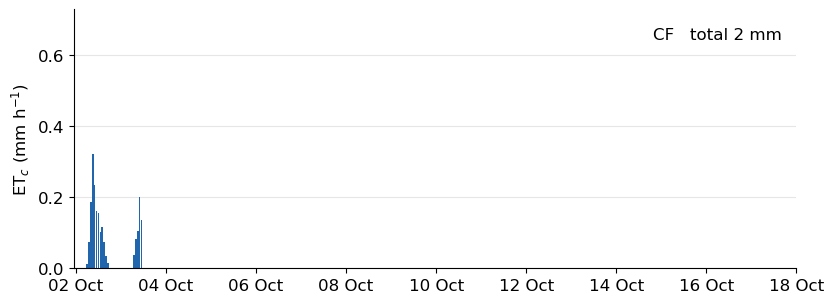

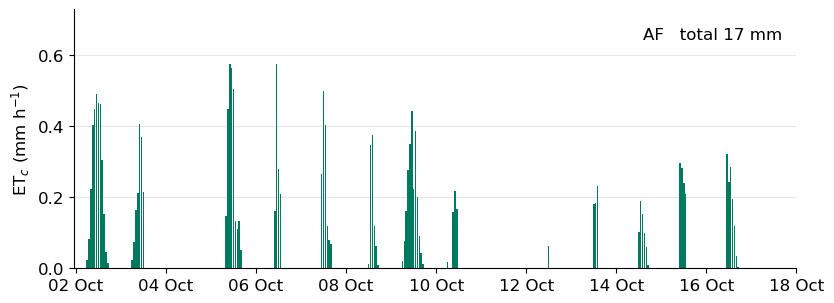

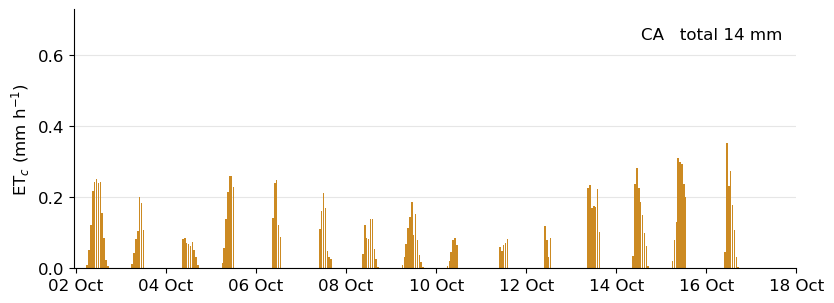

In [27]:
# --- Figures per plot: hourly ET0 (top) + final ETc (bottom), same y-axis ---------------------
import matplotlib.dates as mdates

unit  = r'mm h$^{-1}$' if t1 == 1 else f'mm / {int(t1 * 60)} min'
XLIM  = (pd.Timestamp(START), pd.Timestamp(END))
ts    = pd.to_datetime(out['Timestamp'])
y_et0 = y_etc = YMAX_H   


def style_time(ax, ylabel, ymax):
    ax.set_ylim(0, ymax)
    ax.set_xlim(*XLIM)
    ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='0.9')
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(2, 32, 2)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))


for plot in PLOTS:
    d = out[out['plot'] == plot].assign(ts=ts).set_index('ts').sort_index()

    # 1) actual ETc time series, one figure per plot
    fig, ax = plt.subplots(figsize=(8.5, 3.2))
    ax.bar(d.index, d['ETc'], width=0.8 * t1 / 24, color=COLORS[plot])
    style_time(ax, rf'ET$_c$ ({unit})', y_etc)
    ax.text(0.98, 0.93, f'{plot}   total {d["ETc"].sum():.0f} mm', transform=ax.transAxes,
            ha='right', va='top')
    plt.tight_layout()
    fig.savefig(f'ETc_hourly_{plot}.png', dpi=300, bbox_inches='tight')
    plt.show()

out.to_csv('ETc_results_hourly.csv', index=False)   # hourly ET0, Kc, ETc_pot and final ETc per plot


Days used per plot: {'AF': 16, 'CA': 16, 'CF': 16}


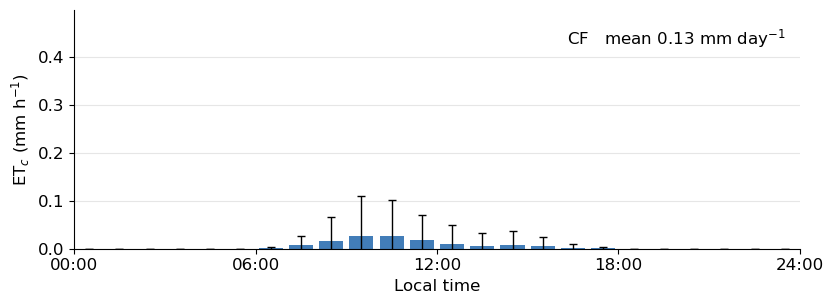

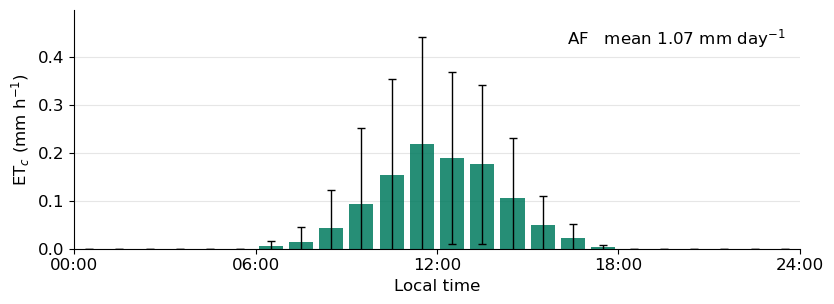

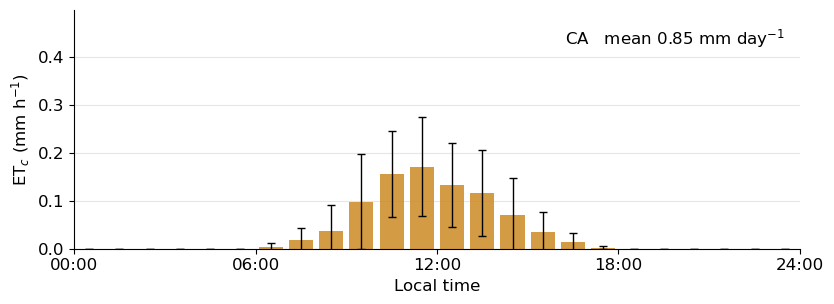

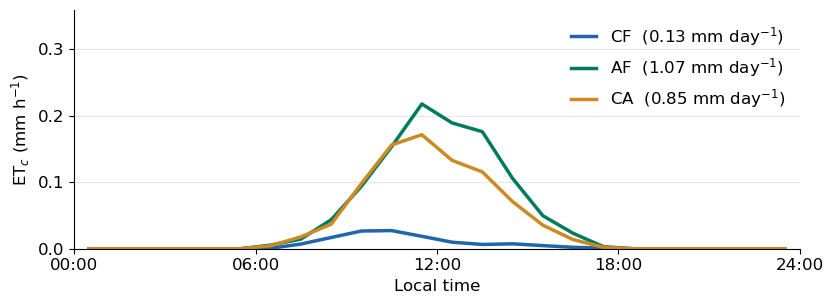

In [28]:
# --- Mean diurnal cycle of the FINAL ETc (after rain/fog and interception), per plot ----------
COMPLETE_DAYS_ONLY = True        # only days with 24 hourly ETc values

unit = r'mm h$^{-1}$' if t1 == 1 else f'mm / {int(t1 * 60)} min'
ts   = pd.to_datetime(out['Timestamp'])
mid  = ts - pd.Timedelta(hours=t1 / 2) if STAMP == 'end' else ts + pd.Timedelta(hours=t1 / 2)
dc   = out.assign(hour=np.floor(out['t']).astype(int), date=mid.dt.date)   # hour = start of the interval

if COMPLETE_DAYS_ONLY:
    dc = dc[dc.groupby(['plot', 'date'])['ETc'].transform('count') == int(round(24 / t1))]
print('Days used per plot:', dc.groupby('plot')['date'].nunique().to_dict())

diurnal_fin    = dc.groupby(['plot', 'hour'])['ETc'].agg(['mean', 'std'])
daily_mean_fin = dc.groupby(['plot', 'date'])['ETc'].sum().groupby('plot').mean()   # [mm/day]
TICKS = range(0, 25, 6)


def style_diu(ax, ymax):
    ax.set_xlim(0, 24)
    ax.set_ylim(0, ymax)
    ax.set_xticks(TICKS, labels=[f'{h:02d}:00' for h in TICKS])
    ax.set_xlabel('Local time')
    ax.set_ylabel(f'ET$_c$ ({unit})')
    ax.grid(axis='y', color='0.9')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


# one figure per plot: mean hourly final ETc (bars) with ±1 SD between days
for plot in PLOTS:
    if plot not in diurnal_fin.index.get_level_values('plot'):
        print(f'{plot}: no complete day of ETc -> no diurnal figure'); continue
    m, s = diurnal_fin.loc[plot, 'mean'], diurnal_fin.loc[plot, 'std']
    fig, ax = plt.subplots(figsize=(8.5, 3.2))
    ax.bar(m.index + t1 / 2, m, width=0.8 * t1, color=COLORS[plot], alpha=0.85,
           yerr=s, capsize=3, error_kw=dict(lw=1.0, capthick=1.0, ecolor='black'))
    ax.text(0.98, 0.93, f'{plot}   mean {daily_mean_fin[plot]:.2f} mm day$^{{-1}}$',
            transform=ax.transAxes, ha='right', va='top')
    style_diu(ax, YMAX_D)                     # same y-axis as the potential ETc diurnal figures
    plt.tight_layout()
    fig.savefig(f'ETc_diurnal_{plot}.png', dpi=300, bbox_inches='tight')
    plt.show()

# the three plots together: mean lines only
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for plot in PLOTS:
    if plot not in diurnal_fin.index.get_level_values('plot'):
        continue
    m = diurnal_fin.loc[plot, 'mean']
    ax.plot(m.index + t1 / 2, m, color=COLORS[plot], lw=2.5,
            label=f'{plot}  ({daily_mean_fin[plot]:.2f} mm day$^{{-1}}$)')
style_diu(ax, YMAX_DM)                        # same y-axis as the potential ETc 'all plots' figure
ax.legend(frameon=False, loc='upper right', handlelength=1.5)
plt.tight_layout()
fig.savefig('ETc_diurnal_all_plots.png', dpi=300, bbox_inches='tight')
plt.show()

diurnal_fin.round(4).to_csv('ETc_diurnal_all_plots.csv')


ET0   ETc
plot J_day            
AF   274    0.00   NaN
     275    3.62  3.12
     276    2.17  1.46
     277    1.69  0.00
     278    3.37  2.67
     279    2.69  1.22
     280    2.84  1.44
     281    2.35  0.93
     282    2.65  2.28
     283    1.28  0.56
     284    1.52  0.00
     285    1.74  0.06
     286    1.83  0.60
     287    1.99  0.61
     288    2.07  1.03
     289    2.41  1.20
     290    0.85  0.00
CA   274    0.00   NaN
     275    3.68  1.65
     276    2.14  0.73
     277    1.69  0.54
     278    3.55  1.17
     279    2.73  0.84
     280    2.90  0.76
     281    2.32  0.69
     282    2.68  0.94
     283    1.21  0.30
     284    1.63  0.33
     285    1.61  0.32
     286    1.72  1.30
     287    1.94  1.28
     288    1.99  1.57
     289    2.20  1.22
     290    0.51  0.00
CF   274    0.00   NaN
     275    1.79  1.49
     276    1.00  0.56
     277    0.86  0.00
     278    2.06  0.00
     279    1.27  0.00
     280    1.42  0.00
     281    1.04  0.00
     282    1.30  0.00
     283    0.63  0.00
     284    0.85  0.00
     285    0.79  0.00
     286    0.80  0.00
     287    1.18  0.00
     288    1.02  0.00
     289    1.00  0.00
     290    0.24  0.00

Total over the period [mm]:


,ET0,ETc
plot,,
AF,35.1,17.2
CA,34.5,13.7
CF,17.2,2.1


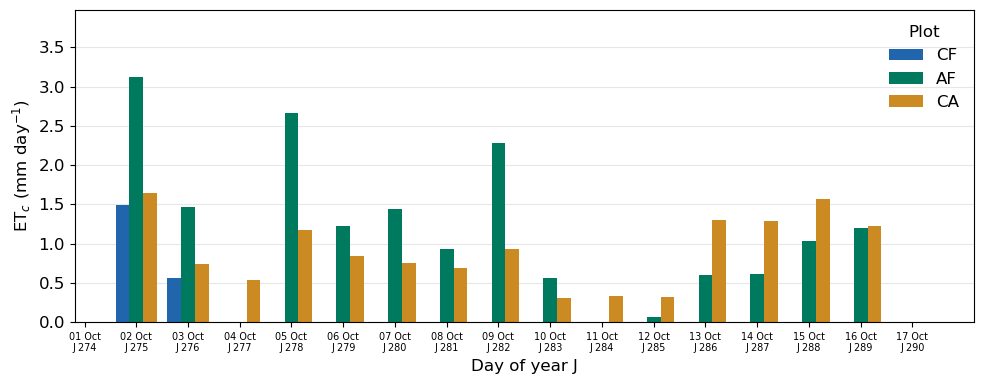

In [29]:
# daily FINAL ETc per plot (bars)
daily_etc_fin = out.groupby(['plot', 'J_day'])[['ET0', 'ETc']].sum(min_count=1)   # [mm/day]

display(daily_etc_fin.round(2))
print('Total over the period [mm]:')
display(daily_etc_fin.groupby('plot')[['ET0', 'ETc']].sum(min_count=1).round(1))

dETc_fin = daily_etc_fin['ETc'].unstack('plot').reindex(columns=PLOTS)   # rows = J, columns = plots in your order
n     = len(PLOTS)
width = 0.8 / n
x     = np.arange(len(dETc_fin))

fig, ax = plt.subplots(figsize=(10, 4))
for k, plot in enumerate(PLOTS):
    ax.bar(x + (k - (n - 1) / 2) * width, dETc_fin[plot], width=width, color=COLORS[plot], label=plot)
ax.set_xticks(x, labels=[f"{pd.Timestamp(YEAR, 1, 1) + pd.Timedelta(days=int(j) - 1):%d %b}\nJ {int(j)}"
                         for j in dETc_fin.index], fontsize=7)
ax.set_xlabel('Day of year J')
ax.set_ylabel(r'ET$_c$ (mm day$^{-1}$)')
ax.set_ylim(0, YMAX_DAY)                      # same scale as the ETc_pot graph
ax.legend(title='Plot', frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig('ETc_daily_per_plot.png', dpi=300, bbox_inches='tight')
plt.show()